In [2]:
import networkx as nx
import numpy as np
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
import random
from collections import Counter
col_dict = {0: 'red', 1: 'blue', 2: 'green', 3: 'orange', 4:'purple', 5:'black', 6:'yellow', 7:'pink', 8:'lightblue',9:'lime', 10:'sienna',11:'indigo'}

## First scenario

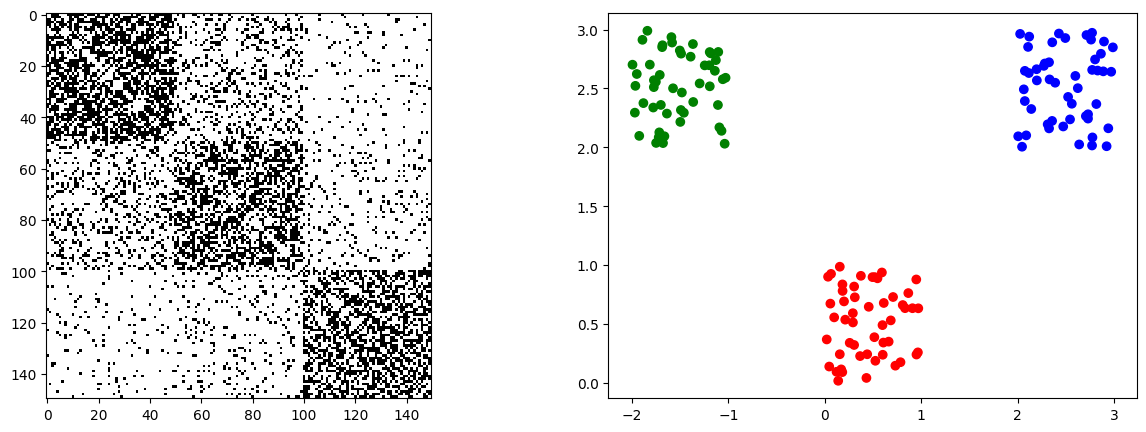

In [47]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,0]=np.random.random_sample(50)
Xg[50:100,0]=np.random.random_sample(50)+2
Xg[100:,0]=np.random.random_sample(50)-2

Xg[:50,1]=np.random.random_sample(50)
Xg[50:100,1]=np.random.random_sample(50)+2
Xg[100:,1]=np.random.random_sample(50)+2
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()


labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

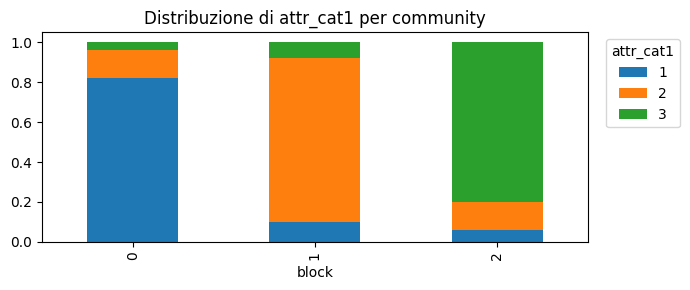

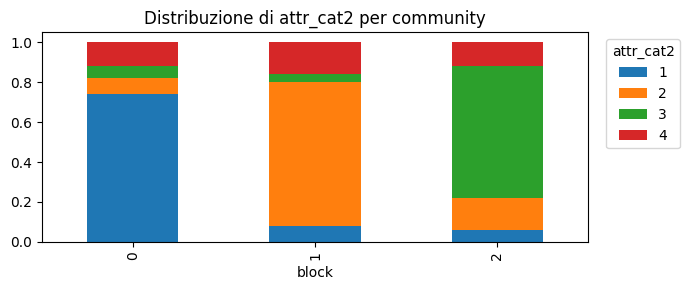

In [48]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [49]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [50]:
for K in Ks:
    print(Rs[K]['vICL'])

-6151.921109964291
-5714.980896212998
-5759.87263835149
-5784.123283272583


In [51]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels_sbm = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels_sbm)

1.0

In [52]:
from scipy.optimize import linear_sum_assignment

def match_labels(true_labels, pred_labels, K):
    """Find the permutation of pred labels that best matches true labels."""
    # Build cost matrix: -overlap between each (true k, pred l) pair
    cost = np.zeros((K, K))
    for k in range(K):
        for l in range(K):
            cost[k, l] = -np.sum((true_labels == k) & (pred_labels == l))
    row_ind, col_ind = linear_sum_assignment(cost)
    # col_ind[k] = which predicted label corresponds to true label k
    return col_ind

perm = match_labels(np.array(labels), pred_labels_sbm, 3)
# perm[k] = estimated label that corresponds to true block k

In [ ]:
np.ix_()

In [56]:
Rs[3]['Theta']

array([[0.50122449, 0.1016    , 0.2128    ],
       [0.1016    , 0.50530612, 0.0536    ],
       [0.2128    , 0.0536    , 0.5877551 ]])

In [57]:
[np.ix_(perm, perm)]

[(array([[2],
         [0],
         [1]]),
  array([[2, 0, 1]]))]

In [53]:
Theta_aligned = Rs[3]['Theta'][np.ix_(perm, perm)]
pi_aligned = Rs[3]['pi'][perm]
mu_aligned = [Rs[3]['mu_list'][perm[k]] for k in range(3)]
Sigma_aligned = [Rs[3]['Sigma_list'][perm[k]] for k in range(3)]
phi_aligned = [phi[perm, :] for phi in Rs[3]['phi_list']]

In [54]:
# Phi vere
[0.8,0.15,0.05]
[0.15,0.8,0.05]
[0.05,0.15,0.8]

[0.7,0.15,0.05,0.1]
[0.15,0.7,0.05,0.1]
[0.05,0.15,0.7,0.1]

# Phi stimate
phi_aligned

[array([[0.82, 0.14, 0.04],
        [0.1 , 0.82, 0.08],
        [0.06, 0.14, 0.8 ]]),
 array([[0.74, 0.08, 0.06, 0.12],
        [0.08, 0.72, 0.04, 0.16],
        [0.06, 0.16, 0.66, 0.12]])]

In [55]:
# Theta vera
[[0.6, 0.2, 0.05],
 [0.2,0.5,0.1],
 [0.05,0.1,0.5]]


# Theta stimata
Theta_aligned

array([[0.5877551 , 0.2128    , 0.0536    ],
       [0.2128    , 0.50122449, 0.1016    ],
       [0.0536    , 0.1016    , 0.50530612]])

### ILouvain con Gower - first

In [25]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [31]:
ARI(list(partition_ilouv.values()), labels)

1.0

### SA cluster first

In [132]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.6565


### STOC cluster first

In [141]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.4624
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 150 clusters
k=7  ARI=0.8183


## Second scenario

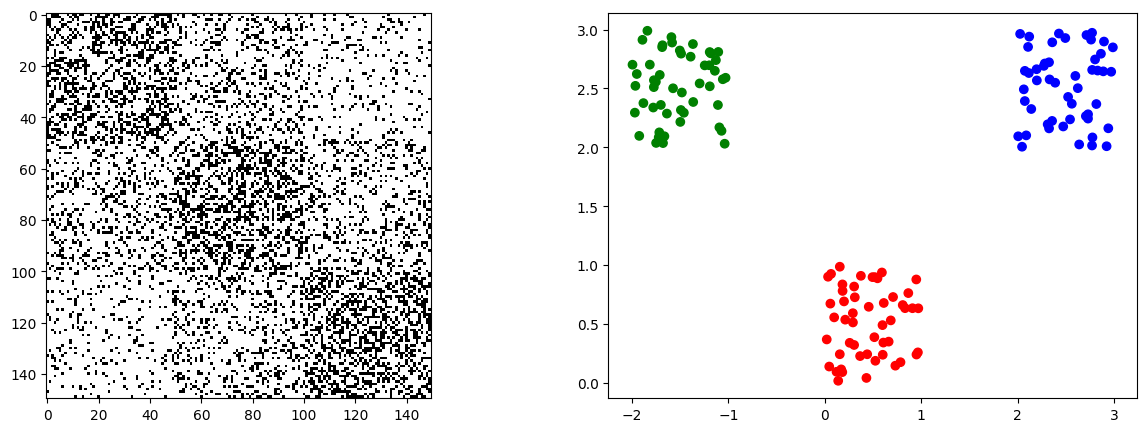

In [38]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.4, 0.2, 0.1],[0.2,0.4,0.2],[0.1,0.2,0.4]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,0]=np.random.random_sample(50)
Xg[50:100,0]=np.random.random_sample(50)+2
Xg[100:,0]=np.random.random_sample(50)-2

Xg[:50,1]=np.random.random_sample(50)
Xg[50:100,1]=np.random.random_sample(50)+2
Xg[100:,1]=np.random.random_sample(50)+2
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()


labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

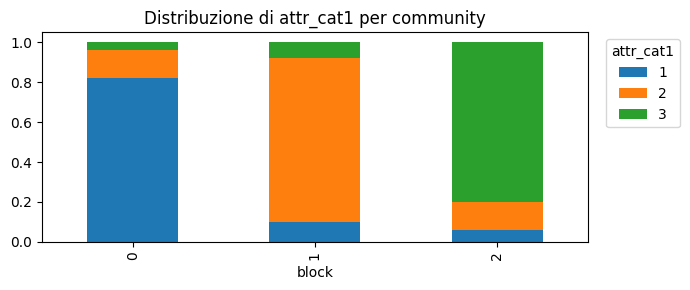

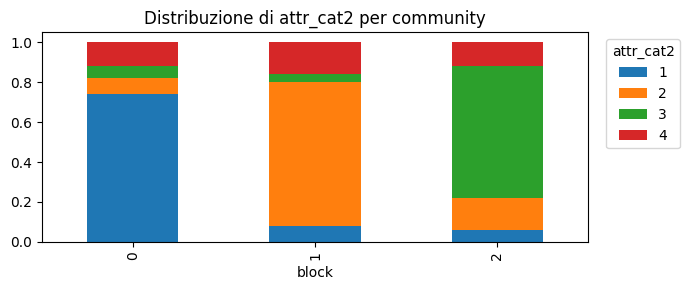

In [39]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [40]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [41]:
for k in Rs.keys():
    print(Rs[k]['vICL'])

-6678.745833587969
-6416.489664924734
-6457.278348775875
-6493.601440399714


In [42]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels)

1.0

In [43]:
from scipy.optimize import linear_sum_assignment

def match_labels(true_labels, pred_labels, K):
    """Find the permutation of pred labels that best matches true labels."""
    # Build cost matrix: -overlap between each (true k, pred l) pair
    cost = np.zeros((K, K))
    for k in range(K):
        for l in range(K):
            cost[k, l] = -np.sum((true_labels == k) & (pred_labels == l))
    row_ind, col_ind = linear_sum_assignment(cost)
    # col_ind[k] = which predicted label corresponds to true label k
    return col_ind

perm = match_labels(np.array(labels), pred_labels_sbm, 3)
# perm[k] = estimated label that corresponds to true block k

In [44]:
Theta_aligned = Rs[3]['Theta'][np.ix_(perm, perm)]
pi_aligned = Rs[3]['pi'][perm]
mu_aligned = [Rs[3]['mu_list'][perm[k]] for k in range(3)]
Sigma_aligned = [Rs[3]['Sigma_list'][perm[k]] for k in range(3)]
phi_aligned = [phi[perm, :] for phi in Rs[3]['phi_list']]

In [ ]:
# Vera:
# [[0.4, 0.2, 0.1],
#  [0.2,0.4,0.2],
#  [0.1,0.2,0.4]]

# Stimata:
Theta_aligned

array([[0.38530612, 0.2128    , 0.1024    ],
       [0.2128    , 0.40653061, 0.206     ],
       [0.1024    , 0.206     , 0.41714286]])

### ILouvain con Gower - second

In [122]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [123]:
ARI(list(partition_ilouv.values()), labels)

0.5228988572603626

### SA cluster second

In [135]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=-0.0052


### STOC cluster second

In [144]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.4624
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 150 clusters
k=7  ARI=0.8183


# Third scenario

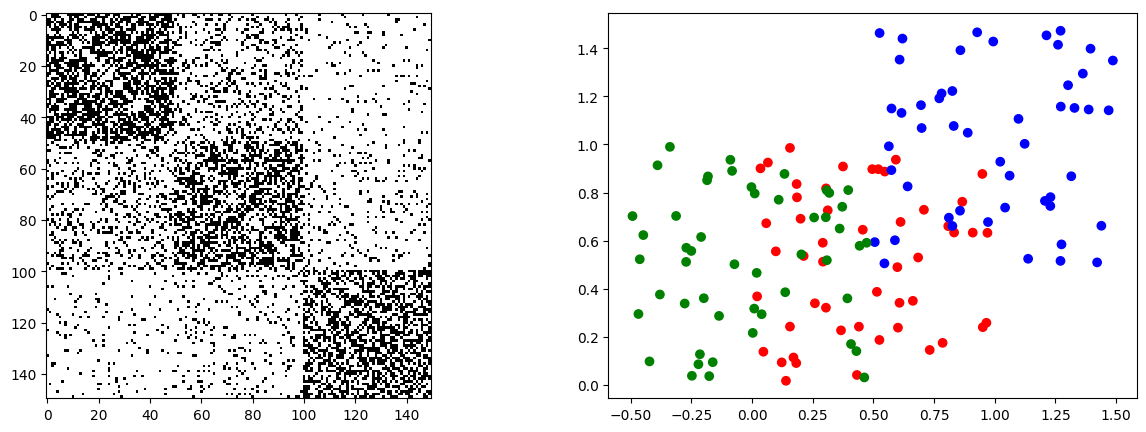

In [27]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.6, 0.2, 0.05],[0.2,0.5,0.1],[0.05,0.1,0.5]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,0]=np.random.random_sample(50)
Xg[50:100,0]=np.random.random_sample(50)+0.5
Xg[100:,0]=np.random.random_sample(50)-0.5

Xg[:50,1]=np.random.random_sample(50)
Xg[50:100,1]=np.random.random_sample(50)+0.5
Xg[100:,1]=np.random.random_sample(50)
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()


labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

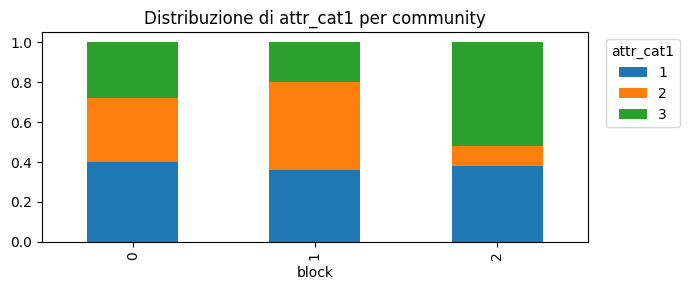

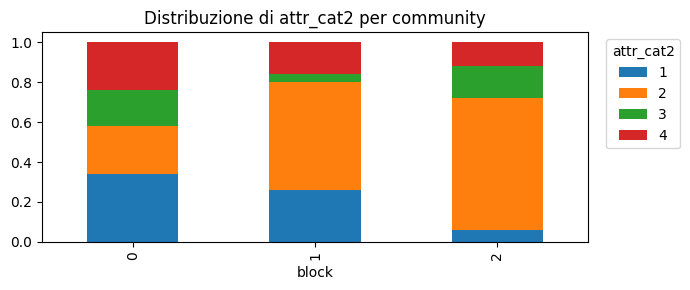

In [28]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.33,0.33,0.34])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.35,0.5,0.15])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.35,0.15,0.5])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.25,0.25,0.25,0.25])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.25,0.6,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.7,0.15,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [29]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [30]:
for k in Rs.keys():
    print(Rs[k]['vICL'])

-6089.244731867563
-5817.425035589147
-5853.514533103009
-5858.140087936817


In [31]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels)

1.0

In [32]:
from scipy.optimize import linear_sum_assignment

def match_labels(true_labels, pred_labels, K):
    """Find the permutation of pred labels that best matches true labels."""
    # Build cost matrix: -overlap between each (true k, pred l) pair
    cost = np.zeros((K, K))
    for k in range(K):
        for l in range(K):
            cost[k, l] = -np.sum((true_labels == k) & (pred_labels == l))
    row_ind, col_ind = linear_sum_assignment(cost)
    # col_ind[k] = which predicted label corresponds to true label k
    return col_ind

perm = match_labels(np.array(labels), pred_labels_sbm, 3)

In [34]:
Theta_aligned = Rs[3]['Theta'][np.ix_(perm, perm)]
pi_aligned = Rs[3]['pi'][perm]
mu_aligned = [Rs[3]['mu_list'][perm[k]] for k in range(3)]
Sigma_aligned = [Rs[3]['Sigma_list'][perm[k]] for k in range(3)]
phi_aligned = [phi[perm, :] for phi in Rs[3]['phi_list']]

In [ ]:
[0.33,0.33,0.34]
[0.35,0.5,0.15]
[0.35,0.15,0.5]

[0.25,0.25,0.25,0.25]
[0.25,0.6,0.05,0.1]
[0.05,0.7,0.15,0.1]

In [36]:
phi_aligned

[array([[0.40000098, 0.32000081, 0.27999821],
        [0.35999912, 0.43999889, 0.20000199],
        [0.38      , 0.1       , 0.52      ]]),
 array([[0.34000085, 0.24000061, 0.18000043, 0.2399981 ],
        [0.25999935, 0.53999863, 0.03999992, 0.1600021 ],
        [0.06      , 0.66      , 0.16      , 0.12      ]])]

### ILouvain con Gower - third

In [114]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [115]:
ARI(list(partition_ilouv.values()), labels)

0.5228988572603626

### SA cluster third

In [138]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.0271


### STOC cluster third

In [147]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.3878
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 150 clusters
k=11  ARI=0.2283


## Fourth scenario

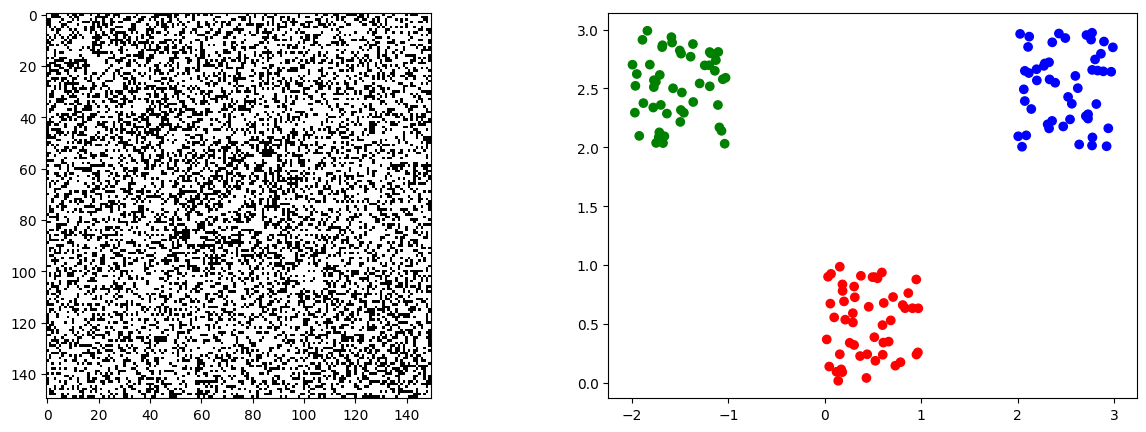

In [148]:
random.seed(42)
size_comm = [50,50,50]
probs = [[0.4, 0.3, 0.3],[0.3,0.4,0.3],[0.3,0.3,0.4]]
G=nx.stochastic_block_model(sizes=size_comm,p=probs,directed=False)

np.random.seed(42)

Xg=np.zeros((150,2))
Xg[:50,0]=np.random.random_sample(50)
Xg[50:100,0]=np.random.random_sample(50)+2
Xg[100:,0]=np.random.random_sample(50)-2

Xg[:50,1]=np.random.random_sample(50)
Xg[50:100,1]=np.random.random_sample(50)+2
Xg[100:,1]=np.random.random_sample(50)+2
Xg=pd.DataFrame(Xg)
A=nx.adjacency_matrix(G).todense()


labels = []
for n,i in enumerate(size_comm):
    labels += [n]*i

A_bool = nx.to_numpy_array(G, dtype=bool)
dtemp = Xg.copy()
dtemp['label'] = labels
dtemp['label'] = dtemp['label'].map(col_dict)
fig, axs = plt.subplots(1,2,figsize=(15,5))
ax0 = axs.flatten()[0]
ax1 = axs.flatten()[1]
ax0.imshow(A_bool, cmap="Greys", interpolation="none")
ax1.scatter(dtemp.loc[:,0],dtemp.loc[:,1],c=dtemp['label'])
plt.show()

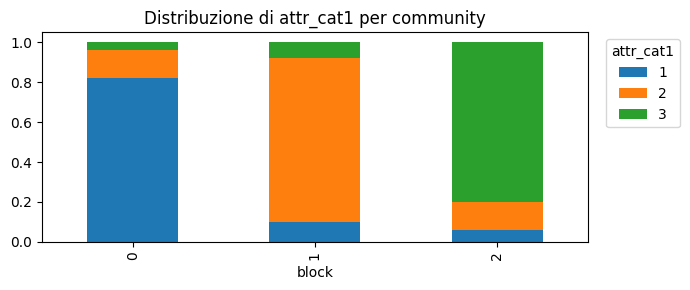

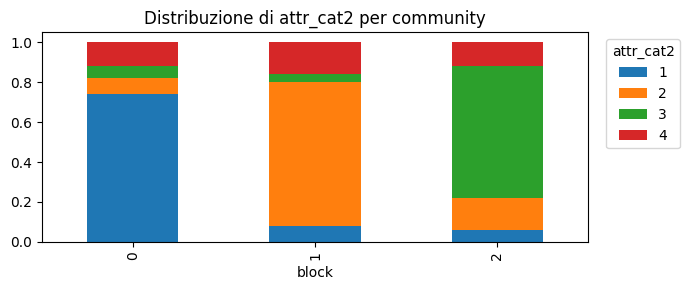

In [149]:
random.seed(42)

Xc = pd.DataFrame(index=range(Xg.shape[0]), columns=['attr_cat1','attr_cat2'])
Xc.loc[:49,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.8,0.15,0.05])
Xc.loc[50:99,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.15,0.8,0.05])
Xc.loc[100:,'attr_cat1'] = random.choices([1,2,3], k=50, weights=[0.05,0.15,0.8])

Xc.loc[:49,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.7,0.15,0.05,0.1])
Xc.loc[50:99,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.15,0.7,0.05,0.1])
Xc.loc[100:,'attr_cat2'] = random.choices([1,2,3,4], k=50, weights=[0.05,0.15,0.7,0.1])

df = Xc.copy()
df["block"] = labels

for col in ["attr_cat1","attr_cat2"]:
    tab = pd.crosstab(df["block"], df[col], normalize="index")
    tab.plot(kind="bar", stacked=True, figsize=(7,3))
    plt.title(f"Distribuzione di {col} per community")
    plt.legend(title=col, bbox_to_anchor=(1.02,1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [150]:
from vem_sbm_new_version import VEM_SBM as VEM_SBM_NEW

Ks = [2,3,4,5]
Rs = {}

for K in Ks:
    fit = VEM_SBM_NEW(A, Xg=Xg, Xc=Xc, K=K, max_iter=50, tol=1e-8, verbose=False)
    Rs[K] = fit
    print(K)

2
3
4
5


In [151]:
for K in Ks:
    print(Rs[K]['vICL'])

-7741.649757943619
-7591.971419243181
-7624.174569424016
-7666.684826878229


In [152]:
from sklearn.metrics.cluster import adjusted_rand_score as ARI

pred_labels_sbm = np.argmax(Rs[3]['r'], axis=1)
ARI(labels, pred_labels_sbm)

1.0

### ILouvain con Gower - fourth

In [158]:
from ILouvain_Gower import ML2Gower

# merge continuous (Xg) and categorical (Xc) into one dict
attributes = {}
for node in G.nodes():
    attributes[node] = {
        0: float(Xg.iloc[node, 0]),     # continuous
        1: float(Xg.iloc[node, 1]),     # continuous
        2: str(Xc.iloc[node, 0]),       # categorical
        3: str(Xc.iloc[node, 1]),       # categorical
    }

attr_types = {0: 'continuous', 1: 'continuous',
              2: 'categorical', 3: 'categorical'}

ml = ML2Gower(G, attributes, {n: n for n in G.nodes()}, attr_types)
partition_ilouv = ml.findPartition()

In [159]:
ARI(list(partition_ilouv.values()), labels)

0.0

### SA cluster fourth

In [156]:
from sa_cluster import sa_cluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

result = sa_cluster(G, k=3, Xg=Xg, Xc=Xc, n_bins=10, 
                    l=20, c=0.15, sigma=0.5, verbose=False)

ari = adjusted_rand_score(labels, result['labels'])
print(f"ARI={ari:.4f}")

ARI=0.0133


### STOC cluster fourth

In [157]:
from stoc import stoc

# auto-tuned
result = stoc(G, Xg=Xg, Xc=Xc, alpha_s=0.3, alpha_t=0.3, verbose=True)

# or manually specified (often better for small graphs)
result = stoc(G, Xg=Xg, Xc=Xc, tau=0.4, l=2)

print(f"k={result['k']}  ARI={ARI(labels, result['labels']):.4f}")

Computing semantic distances ...
  τ = 0.4624
  l = 1
Computing topological distances ...
Running SToC clustering ...
  Found 150 clusters
k=8  ARI=0.8175
